**Data 620 - Week 8**\
Assignment – High Frequency Words

**Yana Rabkova**

**Introduction**

Video presentation link: 



In [1]:
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from nltk.corpus import reuters
from collections import Counter

nltk.download('reuters')

# Load all words from the Reuters corpus
words = reuters.words()

print("Number of documents:", len(reuters.fileids()))
print("Total tokens:", len(words))
print("First 30 tokens:", words[:30])

[nltk_data] Downloading package reuters to
[nltk_data]     /Users/yanarabkova/nltk_data...


Number of documents: 10788
Total tokens: 1720901
First 30 tokens: ['ASIAN', 'EXPORTERS', 'FEAR', 'DAMAGE', 'FROM', 'U', '.', 'S', '.-', 'JAPAN', 'RIFT', 'Mounting', 'trade', 'friction', 'between', 'the', 'U', '.', 'S', '.', 'And', 'Japan', 'has', 'raised', 'fears', 'among', 'many', 'of', 'Asia', "'"]


In [2]:
# Normalize words
clean_words = [
    word.lower()
    for word in words
    if word.isalpha()
]

word_counts = Counter(clean_words)

print("Total word occurrences:", len(clean_words))
print("Unique words:", len(word_counts))

Total word occurrences: 1327141
Unique words: 29173


In [3]:
total_words = len(clean_words)
cumulative_count = 0

for rank, (word, count) in enumerate(
    word_counts.most_common(), start=1
):
    cumulative_count += count

    if cumulative_count >= total_words * 0.5:
        print("Words needed to reach 50%:", rank)
        print("Last word included:", word)
        break

Words needed to reach 50%: 108
Last word included: foreign


In [4]:
top_200 = pd.DataFrame(
    word_counts.most_common(200),
    columns=["Word", "Frequency"]
)

top_200["Rank"] = range(1, 201)

top_200["Relative Frequency"] = (
    top_200["Frequency"] / total_words
)

display(top_200)

,Word,Frequency,Rank,Relative Frequency
0,the,69277,1,0.052200
1,of,36779,2,0.027713
2,to,36400,3,0.027427
3,in,29253,4,0.022042
4,and,25648,5,0.019326
...,...,...,...,...
195,down,885,196,0.000667
196,sources,877,197,0.000661
197,deficit,874,198,0.000659
198,due,871,199,0.000656


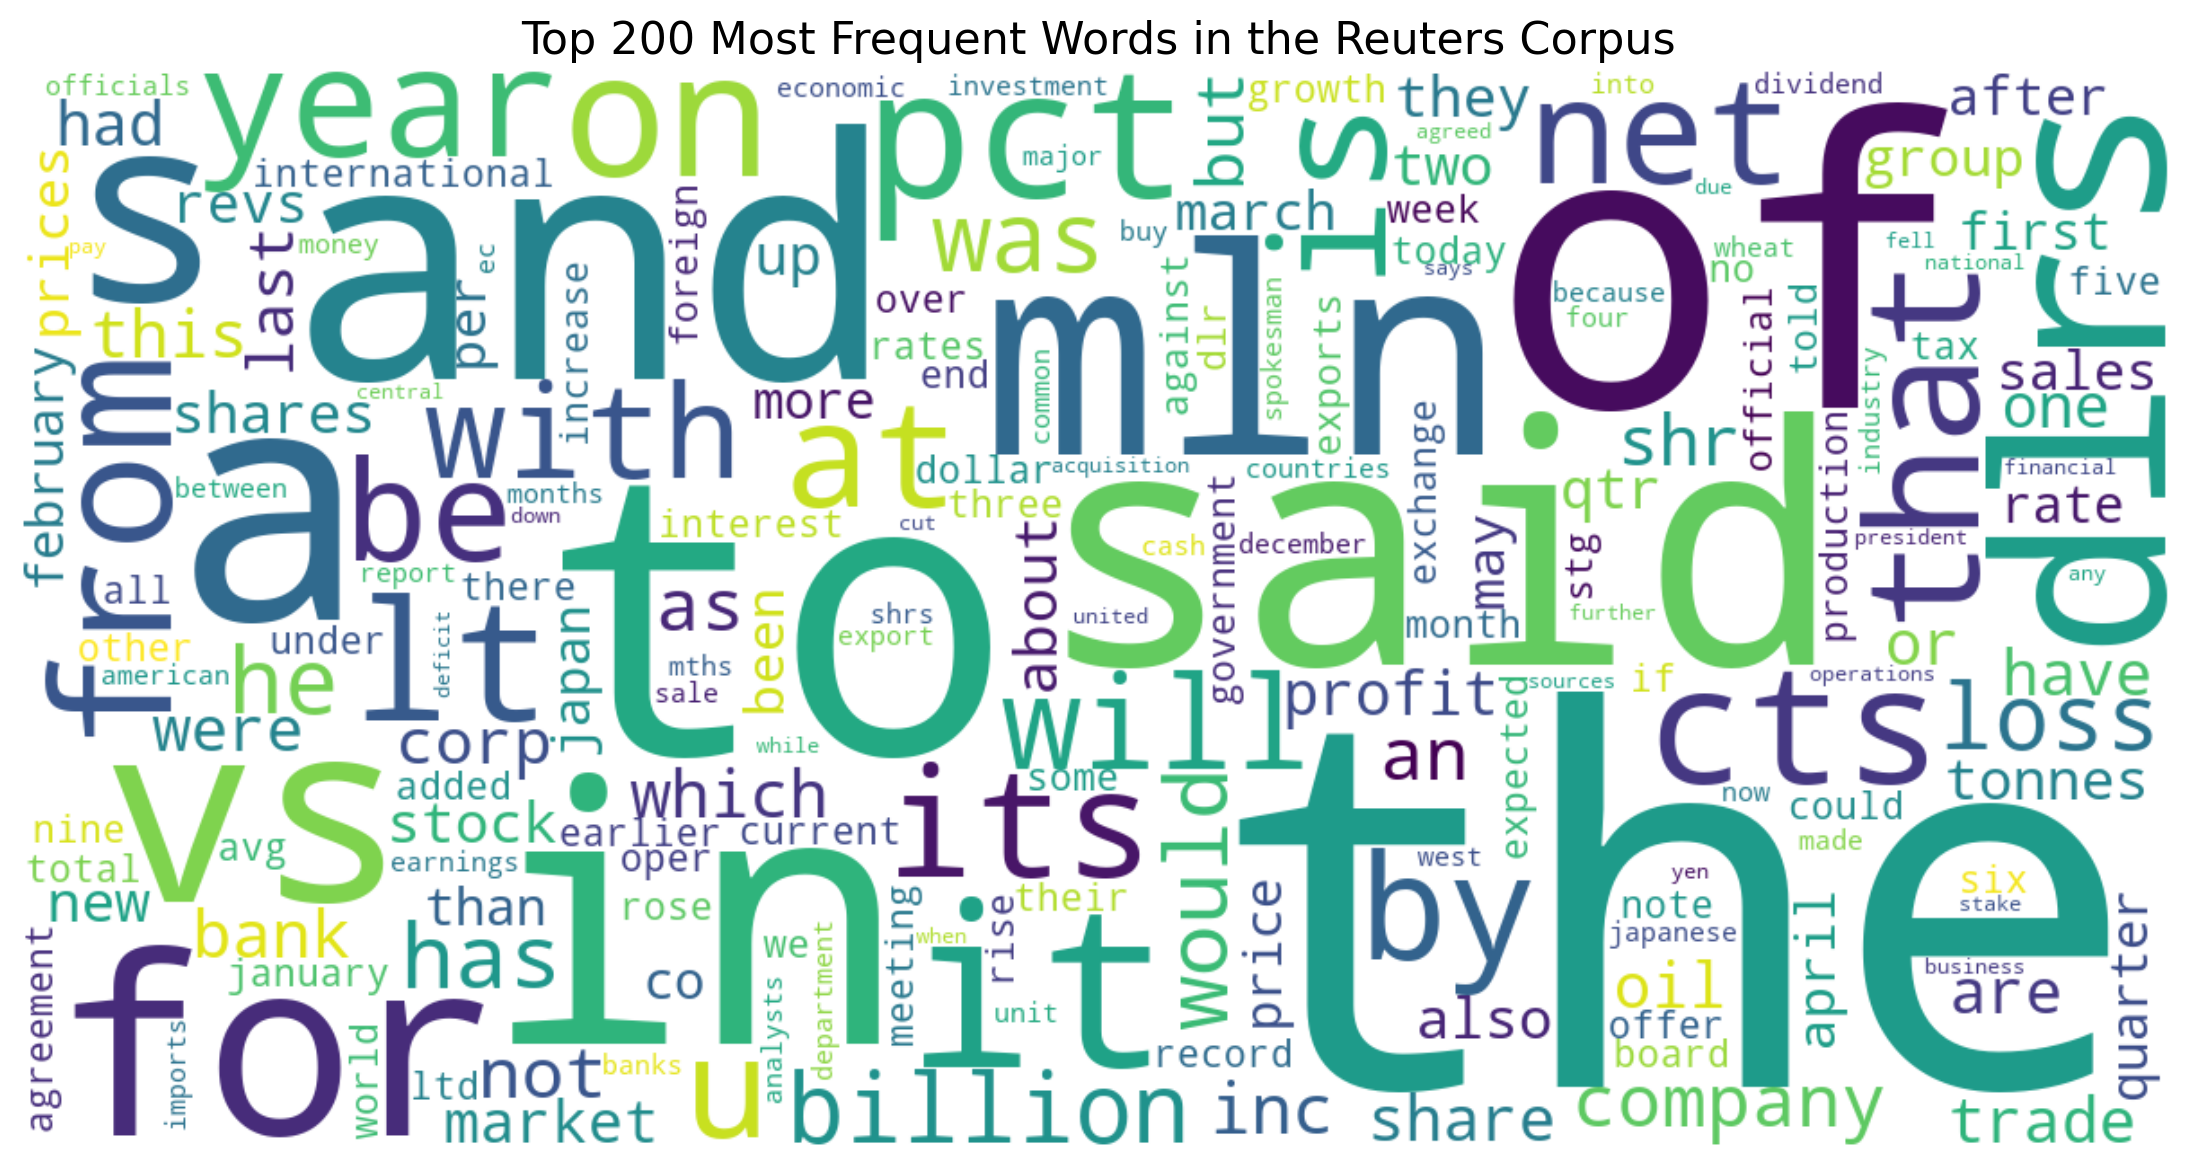

In [8]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

top_200_dict = dict(word_counts.most_common(200))

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=200,
    colormap="viridis",
    random_state=42,
    collocations=False
).generate_from_frequencies(top_200_dict)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Top 200 Most Frequent Words in the Reuters Corpus", fontsize=16)
plt.show()

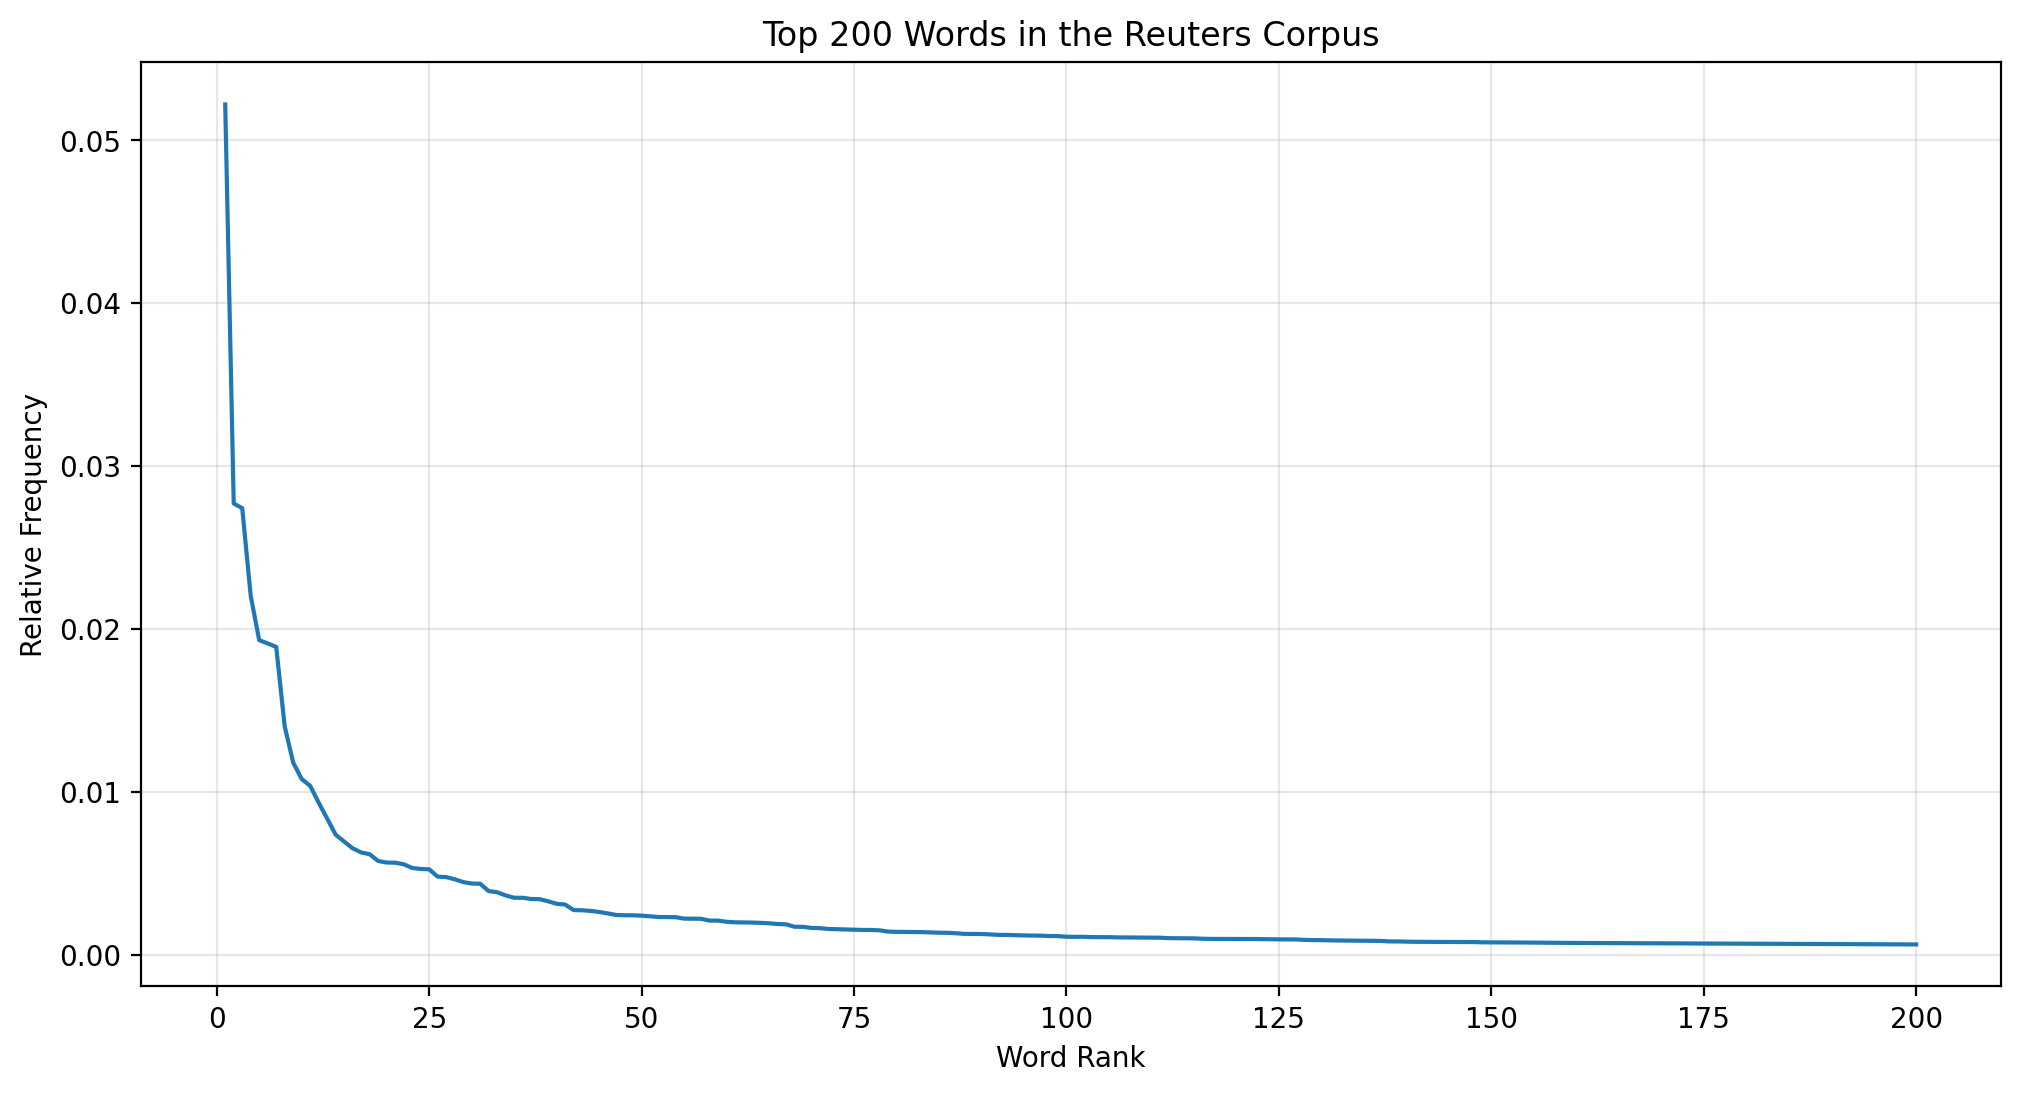

In [5]:
plt.figure(figsize=(12, 6))

plt.plot(
    top_200["Rank"],
    top_200["Relative Frequency"]
)

plt.xlabel("Word Rank")
plt.ylabel("Relative Frequency")
plt.title("Top 200 Words in the Reuters Corpus")
plt.grid(alpha=0.3)
plt.show()

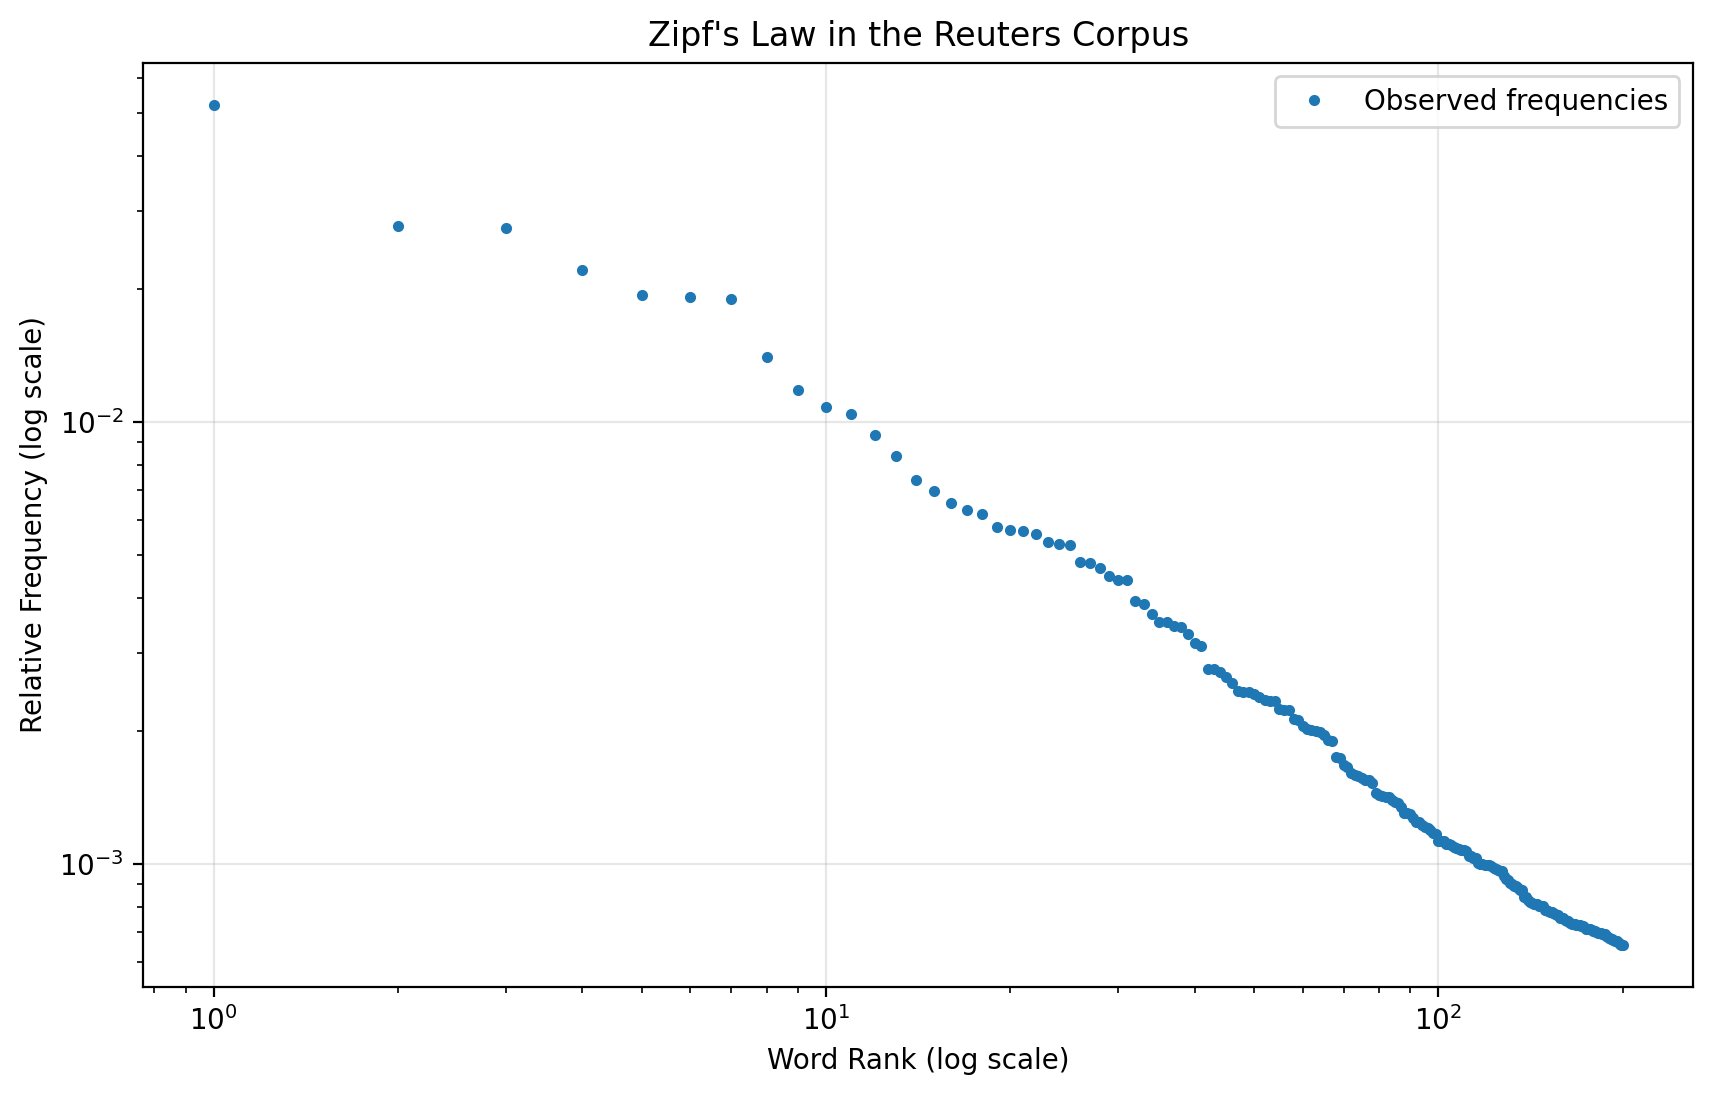

In [6]:
plt.figure(figsize=(10, 6))

plt.loglog(
    top_200["Rank"],
    top_200["Relative Frequency"],
    marker=".",
    linestyle="none",
    label="Observed frequencies"
)

plt.xlabel("Word Rank (log scale)")
plt.ylabel("Relative Frequency (log scale)")
plt.title("Zipf's Law in the Reuters Corpus")
plt.legend()
plt.grid(alpha=0.3)
plt.show()